# Build an adjacency map



In [3]:
%pip install matplotlib cartopy


Note: you may need to restart the kernel to use updated packages.


In [5]:
import os
#print(os.getcwd())

from roadbox_cartopy import Country, City, Road
from roadbox_cartopy import show_map, show_path

In [7]:
with open(f"countries.py", 'r', encoding="utf8") as file:
    countries = eval(file.read())

with open(f"cities.py", 'r', encoding="utf8") as file:
    cities = eval(file.read())

with open(f"roads.py", 'r', encoding="utf8") as file:
    roads = eval(file.read())

with open(f"example_paths.py", 'r', encoding="utf8") as file:
    example_paths = eval(file.read())

verification successful
Paris -> Berlin : 19 cities, 1336.0 km
path length in number of nodes: 19


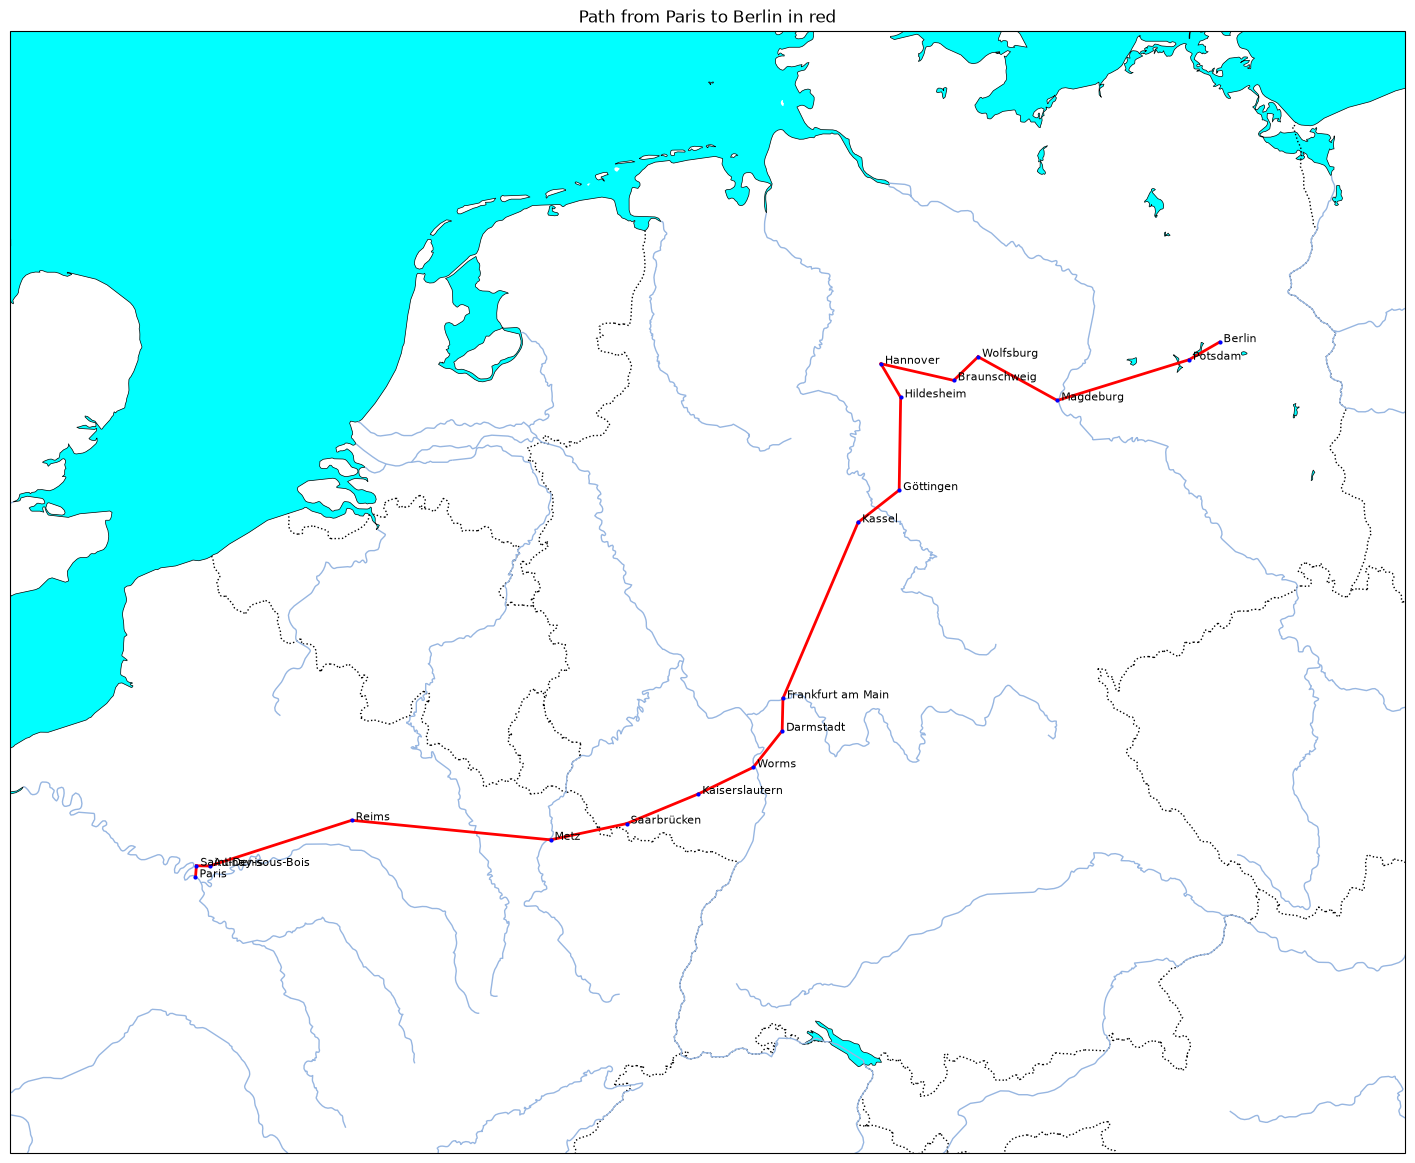

In [8]:


def create_map(roads):
    '''creates an adjacency map'''
    adjacency_map = {}

    for r in roads:

        if not r.a in adjacency_map:
            adjacency_map[r.a] = {}
        adjacency_map[r.a][r.b] = r.distance

        if not r.b in adjacency_map:
            adjacency_map[r.b] = {}
        adjacency_map[r.b][r.a] = r.distance

    return adjacency_map


def verify_map(roads, adjacency_map):
    '''verifies that all roads are properly entered into
    the adjacency map'''
    success = True
    for road in roads:
        if (not road.a in adjacency_map or
            not road.b in adjacency_map or
            not road.a in adjacency_map[road.b] or
            not road.b in adjacency_map[road.a]):
            print("problem with indices of road " + str(road))
            success = False
        else:
            if (not road.distance == adjacency_map[road.a][road.b] or
                not road.distance == adjacency_map[road.b][road.a]):
                print("problem with distance of road " + str(road))
                success = False
    if success:
        print("verification successful")
    else:
        print("verification FAILED")

adjacency_map = create_map(roads)
verify_map(roads, adjacency_map)


def find_city(name):
    '''returns the index of the city with this name'''
    for index, city in cities.items():
        if city.name == name:
            return index


def bfs(adjacency_map, start, goal):
    '''breadth-first search: returns the path with the fewest roads'''
    previous = {start: None}
    queue = [start]
    while len(queue) > 0:
        current = queue.pop(0)
        if current == goal:
            break
        for neighbour in adjacency_map[current]:
            if neighbour not in previous:
                previous[neighbour] = current
                queue.append(neighbour)

    if goal not in previous:
        return None

    path = []
    while goal is not None:
        path.append(goal)
        goal = previous[goal]
    return path[::-1]


start = find_city("Paris")
goal = find_city("Berlin")
path = bfs(adjacency_map, start, goal)

total = sum(adjacency_map[path[i]][path[i + 1]] for i in range(len(path) - 1))
print(cities[start].name, "->", cities[goal].name, ":", len(path), "cities,", total, "km")
show_path(cities, path)